In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/merchant-segmentation-system/Cleaned_Data_Merchant_Level.csv


## <p style="background-color:#191970; font-family:Cursive;color:#FFF9ED;font-size:220%; text-align:center; padding: 10px; border-radius: 15px 55px;">RFM Analysis: Overview 💡</p>


RFM Analysis is a concept used by Data Science professionals, especially in the marketing domain for understanding and segmenting customers based on their buying behaviour.

Using RFM Analysis, a business can assess customers’:

- 📅 Recency (the date they made their last purchase)
- 🔄 Frequency (how often they make purchases)
- 💰 Monetary value (the amount spent on purchases)

Recency, Frequency, and Monetary value of a customer are three key metrics that provide information about customer engagement, loyalty, and value to a business.

To perform RFM analysis using Python, we need a dataset that includes customer IDs, purchase dates, and transaction amounts. With this information, we can calculate RFM values for each customer and analyze their patterns and behaviours.

I found an ideal dataset for this task. You can download the dataset [here](https://www.kaggle.com/datasets/younaniskander/merchant-segmentation-system).

Happy analyzing! 🚀🔍


In [2]:
df = pd.read_csv("/kaggle/input/merchant-segmentation-system/Cleaned_Data_Merchant_Level.csv")
df.head(20)

,Trx_Rank,Points,Trx_Vlu,Trx_Age,Customer_Age,Category In English,User_Id,Mer_Id
0,1,20140,2014.0,362,362,Fashion,21053,0
1,1,11200,1120.0,371,368,Fashion,26472,0
2,2,8500,850.0,368,368,Fashion,26472,0
3,1,1980,198.0,558,34,Fashion,27075,0
4,1,2400,240.0,413,413,Fashion,27417,0
5,1,16740,1674.0,34,34,F&B,1447,1
6,1,5820,582.0,33,33,F&B,2709,1
7,1,4724,472.4,233,233,F&B,3303,1
8,1,1565,156.5,14,14,F&B,7026,1
9,1,4165,416.5,27,27,F&B,10231,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43672 entries, 0 to 43671
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Trx_Rank             43672 non-null  int64  
 1   Points               43672 non-null  int64  
 2   Trx_Vlu              43672 non-null  float64
 3   Trx_Age              43672 non-null  int64  
 4   Customer_Age         43672 non-null  int64  
 5   Category In English  43672 non-null  object 
 6   User_Id              43672 non-null  int64  
 7   Mer_Id               43672 non-null  int64  
dtypes: float64(1), int64(6), object(1)
memory usage: 2.7+ MB


In [4]:
df["Trx_Rank"].value_counts()

1     36348
2      5079
3      1301
4       497
5       200
6       101
7        57
8        33
9        21
10       13
11       10
12        6
13        2
14        1
15        1
16        1
17        1
Name: Trx_Rank, dtype: int64

In [5]:
df.isna().sum()

Trx_Rank               0
Points                 0
Trx_Vlu                0
Trx_Age                0
Customer_Age           0
Category In English    0
User_Id                0
Mer_Id                 0
dtype: int64

In [6]:
df =df.reset_index(drop=True)

In [7]:
duplicates = df[df.duplicated()]
duplicates

,Trx_Rank,Points,Trx_Vlu,Trx_Age,Customer_Age,Category In English,User_Id,Mer_Id


In [8]:
df.describe()

,Trx_Rank,Points,Trx_Vlu,Trx_Age,Customer_Age,User_Id,Mer_Id
count,43672.000000,43672.000000,43672.000000,43672.000000,43672.000000,43672.000000,43672.000000
mean,1.265227,3312.249748,331.224975,185.186664,144.027844,17173.411889,16.277111
std,0.776549,5756.374137,575.637414,121.989540,114.764448,9665.399084,16.099288
min,1.000000,20.000000,2.000000,1.000000,1.000000,0.000000,0.000000
25%,1.000000,1220.000000,122.000000,62.000000,34.000000,8710.750000,8.000000
50%,1.000000,1893.500000,189.350000,203.000000,115.000000,17561.000000,8.000000
75%,1.000000,3100.000000,310.000000,271.000000,252.000000,25634.250000,26.000000
max,17.000000,263800.000000,26380.000000,698.000000,682.000000,33518.000000,56.000000


In [9]:
for column in df.select_dtypes(include= ["object"]):
    print(f"Unique values in {column} : {df[column].unique()}")

Unique values in Category In English : ['Fashion' 'F&B' 'Other' 'Grocery' 'Transportaion' 'Electronics'
 'Health & Beauty']


In [10]:
num_col = ['Trx_Rank','Points','Trx_Vlu','Trx_Age','Customer_Age','User_Id','Mer_Id']
num_df = df[num_col]

In [11]:
def detect_outliers(column):
    q1 = column.quantile(0.25)
    q3 = column.quantile(0.75)
    iqr = q3 -q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = column[(column < lower_bound) | (column > upper_bound)]
    return outliers


In [12]:
# Detect outliers for each column
outliers_dict = {}
for column in num_df.columns:
    outliers = detect_outliers(num_df[column])
    outliers_dict[column] = outliers

# Print the detected outliers for each column
for column, outliers in outliers_dict.items():
    if not outliers.empty:
        print(f"Outliers in {column}:")
        print(outliers)
        print()

Outliers in Trx_Rank:
2        2
19       2
22       2
27       2
34       2
        ..
43622    3
43656    2
43657    4
43666    2
43671    2
Name: Trx_Rank, Length: 7324, dtype: int64

Outliers in Points:
0        20140
1        11200
2         8500
5        16740
10        9491
         ...  
43591     6225
43626    21320
43642    11040
43643     6940
43666     6500
Name: Points, Length: 4644, dtype: int64

Outliers in Trx_Vlu:
0        2014.0
1        1120.0
2         850.0
5        1674.0
10        949.1
          ...  
43591     622.5
43626    2132.0
43642    1104.0
43643     694.0
43666     650.0
Name: Trx_Vlu, Length: 4644, dtype: float64

Outliers in Trx_Age:
7201     644
7953     655
7967     682
9024     586
9572     641
10035    593
10345    615
30967    698
30968    647
31416    642
38799    644
39281    625
Name: Trx_Age, dtype: int64

Outliers in Customer_Age:
7201    644
7967    682
Name: Customer_Age, dtype: int64

Outliers in Mer_Id:
39360    54
39361    54
39362    5

In [13]:
import pandas as pd
import numpy as np
import plotly.express as px

# Assuming you have loaded your data into a DataFrame called df
# Let's focus on the numeric columns only for outlier detection
numeric_columns = ['Trx_Rank', 'Points', 'Trx_Vlu', 'Trx_Age', 'Customer_Age', 'User_Id', 'Mer_Id']
numeric_df = df[numeric_columns]

# Function to add some random outliers to the numeric DataFrame for demonstration purposes
def add_random_outliers(column):
    # Generating random outliers between a specific range
    num_outliers = 5
    lower_bound = column.min() - 500
    upper_bound = column.max() + 500
    random_outliers = np.random.randint(lower_bound, upper_bound, num_outliers)
    
    # Appending the random outliers to the column
    column_with_outliers = column.copy()
    column_with_outliers = column_with_outliers.append(pd.Series(random_outliers))
    return column_with_outliers



In [14]:

# # Add random outliers to the numeric DataFrame (for demonstration purposes)
# num_df_with_outliers = numeric_df.apply(add_random_outliers)

# # Function to detect outliers using IQR method
# def detect_outliers(column):
#     q1 = column.quantile(0.25)
#     q3 = column.quantile(0.75)
#     iqr = q3 - q1
#     lower_bound = q1 - 1.5 * iqr
#     upper_bound = q3 + 1.5 * iqr
#     outliers = column[(column < lower_bound) | (column > upper_bound)]
#     return outliers

# # Detect outliers for each column
# outliers_dict = {}
# for column in num_df_with_outliers.columns:
#     outliers = detect_outliers(num_df_with_outliers[column])
#     outliers_dict[column] = outliers

# # Count the number of outliers in each column
# outliers_count = {column: len(outliers) for column, outliers in outliers_dict.items()}



In [15]:
# # Create a bar plot using Plotly Express
# fig = px.bar(x=list(outliers_count.keys()), y=list(outliers_count.values()), 
#              labels={'x': 'Columns', 'y': 'Number of Outliers'},
#              title='Number of Outliers Detected in Each Column')
# fig.show()

In [16]:
# # Function to cap outliers to the upper and lower bounds
# def cap_outliers(column):
#     q1 = column.quantile(0.25)
#     q3 = column.quantile(0.75)
#     iqr = q3 - q1
#     lower_bound = q1 - 1.5 * iqr
#     upper_bound = q3 + 1.5 * iqr
#     capped_values = column.clip(lower_bound, upper_bound)
#     return capped_values

In [17]:
# # Cap outliers to the upper and lower bounds for each column
# for column in numeric_df.columns:
#     df[column] = cap_outliers(df[column])

# # After handling outliers, you can recompute summary statistics:
# df.describe()

In [18]:
# # Create a bar plot using Plotly Express
# fig = px.bar(x=list(outliers_count.keys()), y=list(outliers_count.values()), 
#              labels={'x': 'Columns', 'y': 'Number of Outliers'},
#              title='Number of Outliers Detected in Each Column')
# fig.show()

# **business questions**

In [19]:
cat = df.select_dtypes(include=object)
cat.value_counts()


Category In English
Grocery                30694
F&B                     7720
Fashion                 3333
Health & Beauty         1504
Electronics              228
Transportaion            146
Other                     47
dtype: int64

In [20]:
df.columns

Index(['Trx_Rank', 'Points', 'Trx_Vlu', 'Trx_Age', 'Customer_Age',
       'Category In English', 'User_Id', 'Mer_Id'],
      dtype='object')

In [21]:
pip install -U kaleido

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 MB 16.7 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [22]:
# Question 1: What is the total transaction volume (Trx_Vlu) for each category?

import plotly.express as px

category_trx_volume = df.groupby('Category In English')['Trx_Vlu'].sum().reset_index()
fig1 = px.bar(category_trx_volume, x='Category In English', y='Trx_Vlu', title='Total Transaction Volume by Category')

fig1.show()



In [23]:
category_avg_trx_age = df.groupby('Category In English')['Trx_Age'].mean().reset_index()
fig2 = px.bar(category_avg_trx_age, x='Category In English', y='Trx_Age', title='Average Transaction Age by Category')
fig2.show()

# **What is the total transaction value (Trx_Vlu) for each merchant (Mer_Id)?**

In [24]:
merchant_trx_value = df.groupby('Mer_Id')['Trx_Vlu'].sum().reset_index()
fig8 = px.bar(merchant_trx_value, x='Mer_Id', y='Trx_Vlu', title='Total Transaction Value by Merchant')
fig8.show()

# **What is the distribution of transaction ranks in the "Fashion" category?**

In [25]:
df_fashion = df[df['Category In English'] == 'Fashion']
result_rank = df_fashion.groupby('Trx_Rank').size().reset_index(name='Count')

fig_rank = px.bar(result_rank, x='Trx_Rank', y='Count', title='Distribution of Transaction Ranks in Fashion Category')
fig_rank.update_layout(yaxis_type='log')  # Set the y-axis to log scale

fig_rank.show()


In [26]:
df.to_csv("cus_add.csv", index=False)

In [27]:
cus_trans = pd.read_csv('/kaggle/working/cus_add.csv')
cus_trans.head()

,Trx_Rank,Points,Trx_Vlu,Trx_Age,Customer_Age,Category In English,User_Id,Mer_Id
0,1,20140,2014.0,362,362,Fashion,21053,0
1,1,11200,1120.0,371,368,Fashion,26472,0
2,2,8500,850.0,368,368,Fashion,26472,0
3,1,1980,198.0,558,34,Fashion,27075,0
4,1,2400,240.0,413,413,Fashion,27417,0


In [28]:
# sorted(df['Customer_Age'].unique())

In [29]:
cus_trans.isna().sum()

Trx_Rank               0
Points                 0
Trx_Vlu                0
Trx_Age                0
Customer_Age           0
Category In English    0
User_Id                0
Mer_Id                 0
dtype: int64

In [30]:
import pandas as pd
from datetime import datetime  # Import the datetime module

# Apply the conversion function to 'Customer_Age' column
# df['Customer_Age'] = df['Customer_Age'].apply(convert_to_numeric)

# Filter out rows with lists in 'Customer_Age' column and perform groupby operation
rfm_table = df.groupby('User_Id').agg({
    'Customer_Age': lambda x: df['Customer_Age'].max() - x.min(),
    'Trx_Rank': lambda x: len(x),
    'Points': lambda x: sum(x)
})

rfm_table


,Customer_Age,Trx_Rank,Points
User_Id,,,
0,401,1,4427
1,648,1,2490
2,446,1,3000
3,362,1,1620
4,275,1,700
...,...,...,...
33514,581,3,5940
33515,438,1,480
33516,426,1,1320


In [31]:
rfm_table.rename(columns={'Customer_Age':'Recency' , 'Trx_Rank':'Frequency' , 'Points':'Monetary'}, inplace=True)

In [32]:
rfm_table

,Recency,Frequency,Monetary
User_Id,,,
0,401,1,4427
1,648,1,2490
2,446,1,3000
3,362,1,1620
4,275,1,700
...,...,...,...
33514,581,3,5940
33515,438,1,480
33516,426,1,1320


In [33]:
import pandas as pd
from datetime import datetime  # Import the datetime module

# Assuming rfm_table is your DataFrame containing the data

# Drop rows with missing values from 'Recency', 'Frequency', and 'Monetary' columns
rfm_table_cleaned = rfm_table.dropna(subset=['Recency', 'Frequency', 'Monetary'])

# Convert the 'Recency' column to numeric (assuming it contains either numeric values or lists)
rfm_table_cleaned['Recency_numeric'] = rfm_table_cleaned['Recency'].apply(lambda x: x if isinstance(x, int) else x[0] if isinstance(x, list) else x)

# Create the 'r_score' column using qcut with custom labels based on 'Recency_numeric'
rfm_table_cleaned['r_score'] = pd.qcut(rfm_table_cleaned['Recency_numeric'], 4, labels=['4', '3', '2', '1'])

# Create custom bins for the 'f_score' column
bins = [0, 1, 2, 10e6]  # Adjust the bin ranges as needed
rfm_table_cleaned['f_score'] = pd.cut(rfm_table_cleaned['Frequency'], bins, labels=['1', '2', '3'])

# Create the 'm_score' column using qcut with custom labels
rfm_table_cleaned['m_score'] = pd.qcut(rfm_table_cleaned['Monetary'], 4, labels=['1', '2', '3', '4'])

# Display the cleaned DataFrame with the new 'r_score', 'f_score', and 'm_score' columns
print(rfm_table_cleaned)


         Recency  Frequency  Monetary  Recency_numeric r_score f_score m_score
User_Id                                                                       
0            401          1      4427              401       4       1       4
1            648          1      2490              648       1       1       3
2            446          1      3000              446       3       1       3
3            362          1      1620              362       4       1       2
4            275          1       700              275       4       1       1
...          ...        ...       ...              ...     ...     ...     ...
33514        581          3      5940              581       2       3       4
33515        438          1       480              438       3       1       1
33516        426          1      1320              426       3       1       1
33517        669          1      2100              669       1       1       2
33518        627          3      5680              6

In [34]:
import pandas as pd
import plotly.express as px

# Assuming rfm_table is your DataFrame containing the data

# Convert 'Recency' and 'Monetary' columns to numeric (if they contain lists)
rfm_table['Recency'] = rfm_table['Recency'].apply(lambda x: x if isinstance(x, int) else x[0] if isinstance(x, list) else x)

# Melt the DataFrame to create a long-form representation
melted_rfm = pd.melt(rfm_table, id_vars=['Recency'], value_vars=['Monetary'], var_name='Metric', value_name='Value')

# Create the scatter plot using Plotly Express
fig = px.scatter(melted_rfm,log_y=True ,  x='Recency', y='Value', color='Metric', title='Recency vs Monetary')

# Show the plot
fig.show()


In [35]:
import pandas as pd
import plotly.express as px

# Assuming rfm_table is your DataFrame containing the data

# Convert 'Recency' and 'Monetary' columns to numeric (if they contain lists)
rfm_table['Recency'] = rfm_table['Recency'].apply(lambda x: x if isinstance(x, int) else x[0] if isinstance(x, list) else x)

# Melt the DataFrame to create a long-form representation
melted_rfm = pd.melt(rfm_table, id_vars=['Frequency'], value_vars=['Monetary'], var_name='Metric', value_name='Value')

# Create the scatter plot using Plotly Express
fig = px.scatter(melted_rfm,log_y=True ,  x='Frequency', y='Value', color='Metric', title='Frequency vs Monetary')

# Show the plot
fig.show()


In [36]:
rfm_table_cleaned['rfm_score'] = 100 * rfm_table_cleaned['r_score'].astype(int) + 10 * rfm_table_cleaned['f_score'].astype(int) + rfm_table_cleaned['m_score'].astype(int)
rfm_table_cleaned

,Recency,Frequency,Monetary,Recency_numeric,r_score,f_score,m_score,rfm_score
User_Id,,,,,,,,
0,401,1,4427,401,4,1,4,414
1,648,1,2490,648,1,1,3,113
2,446,1,3000,446,3,1,3,313
3,362,1,1620,362,4,1,2,412
4,275,1,700,275,4,1,1,411
...,...,...,...,...,...,...,...,...
33514,581,3,5940,581,2,3,4,234
33515,438,1,480,438,3,1,1,311
33516,426,1,1320,426,3,1,1,311


In [37]:
rfm_table_cleaned[['r_score', 'f_score', 'm_score']]

,r_score,f_score,m_score
User_Id,,,
0,4,1,4
1,1,1,3
2,3,1,3
3,4,1,2
4,4,1,1
...,...,...,...
33514,2,3,4
33515,3,1,1
33516,3,1,1


In [38]:
rfm_table_cleaned['frist_segment'] = pd.qcut(rfm_table_cleaned['rfm_score'],4,['bronze','silver','gold','platinum'])
rfm_table_cleaned

,Recency,Frequency,Monetary,Recency_numeric,r_score,f_score,m_score,rfm_score,frist_segment
User_Id,,,,,,,,,
0,401,1,4427,401,4,1,4,414,platinum
1,648,1,2490,648,1,1,3,113,bronze
2,446,1,3000,446,3,1,3,313,gold
3,362,1,1620,362,4,1,2,412,platinum
4,275,1,700,275,4,1,1,411,gold
...,...,...,...,...,...,...,...,...,...
33514,581,3,5940,581,2,3,4,234,silver
33515,438,1,480,438,3,1,1,311,silver
33516,426,1,1320,426,3,1,1,311,silver


In [39]:
import plotly.express as px

# Assuming rfm_table_cleaned is your DataFrame containing the data with 'frist_segment' column
fig = px.histogram(rfm_table_cleaned, x='frist_segment', title='RFM Segments Count')

# Show the plot
fig.show()


In [40]:
def customer_segmenation(rfm_score):
  if rfm_score == 444:
    return '# VIP customer'
  elif  rfm_score >= 433 and rfm_score < 444:
    return '# very Loyal customer'
  elif   rfm_score >=421 and rfm_score< 433:
    return 'become loyal customer'
  elif rfm_score>=344 and rfm_score < 421:
    return 'recent customer'
  elif rfm_score>=323 and rfm_score<344:
    return 'Potential customer'
  elif rfm_score>=224 and rfm_score<311:
    return 'high risk to churn'
  else:
    return 'Lossing customer'       
    

rfm_table_cleaned['customer_segmenation'] = rfm_table_cleaned['rfm_score'].apply(customer_segmenation)
rfm_table_cleaned


,Recency,Frequency,Monetary,Recency_numeric,r_score,f_score,m_score,rfm_score,frist_segment,customer_segmenation
User_Id,,,,,,,,,,
0,401,1,4427,401,4,1,4,414,platinum,recent customer
1,648,1,2490,648,1,1,3,113,bronze,Lossing customer
2,446,1,3000,446,3,1,3,313,gold,Lossing customer
3,362,1,1620,362,4,1,2,412,platinum,recent customer
4,275,1,700,275,4,1,1,411,gold,recent customer
...,...,...,...,...,...,...,...,...,...,...
33514,581,3,5940,581,2,3,4,234,silver,high risk to churn
33515,438,1,480,438,3,1,1,311,silver,Lossing customer
33516,426,1,1320,426,3,1,1,311,silver,Lossing customer


In [41]:
import pandas as pd

# Display the columns in the rfm_table_cleaned DataFrame
print(rfm_table_cleaned.columns)


Index(['Recency', 'Frequency', 'Monetary', 'Recency_numeric', 'r_score',
       'f_score', 'm_score', 'rfm_score', 'frist_segment',
       'customer_segmenation'],
      dtype='object')


In [42]:
import pandas as pd
import plotly.express as px

# Assuming you have a DataFrame called rfm_table_cleaned with a column named 'customer_segmenation'
# and it looks something like this:
# rfm_table_cleaned = pd.DataFrame({'customer_segmenation': ['Segment1', 'Segment2', 'Segment1', 'Segment3', 'Segment2', 'Segment1']})

# Convert the 'customer_segmenation' column to categorical data type
rfm_table_cleaned['customer_segmenation'] = pd.Categorical(rfm_table_cleaned['customer_segmenation'])

# Get the count of each customer_segmentation category
segment_counts = rfm_table_cleaned['customer_segmenation'].value_counts().reset_index()
segment_counts.columns = ['customer_segmenation', 'count']

# Create a bar plot using Plotly Express
fig = px.bar(segment_counts, x='customer_segmenation', y='count', title='Customer Segmentation Count', labels={'customer_segmenation': 'Customer Segmentation', 'count': 'Count'})

# Rotate x-axis labels for better readability
fig.update_xaxes(tickangle=45)

# Show the plot
fig.show()


In [43]:
import pandas as pd
import plotly.express as px

# Assuming you have a DataFrame called rfm_table_cleaned with a column named 'customer_segmenation'
# and it looks something like this:
# rfm_table_cleaned = pd.DataFrame({'customer_segmenation': ['Segment1', 'Segment2', 'Segment1', 'Segment3', 'Segment2', 'Segment1']})

# Convert the 'customer_segmenation' column to categorical data type
rfm_table_cleaned['customer_segmenation'] = pd.Categorical(rfm_table_cleaned['customer_segmenation'])

# Get the count of each customer_segmentation category
segment_counts = rfm_table_cleaned['customer_segmenation'].value_counts().reset_index()
segment_counts.columns = ['customer_segmenation', 'count']

# Create a 3D scatter plot using Plotly Express
fig = px.scatter_3d(segment_counts, x='customer_segmenation', y='count', z='count', title='Customer Segmentation Count', labels={'customer_segmenation': 'Customer Segmentation', 'count': 'Count'})

# Rotate x-axis labels for better readability
fig.update_layout(scene=dict(xaxis=dict(tickangle=45)))

# Show the plot
fig.show()


In [44]:
data = rfm_table[['Recency','Frequency','Monetary']]
data = data.reset_index()
data

,User_Id,Recency,Frequency,Monetary
0,0,401,1,4427
1,1,648,1,2490
2,2,446,1,3000
3,3,362,1,1620
4,4,275,1,700
...,...,...,...,...
33452,33514,581,3,5940
33453,33515,438,1,480
33454,33516,426,1,1320
33455,33517,669,1,2100


In [45]:
new_data = data.drop('User_Id',axis=1)
new_data

,Recency,Frequency,Monetary
0,401,1,4427
1,648,1,2490
2,446,1,3000
3,362,1,1620
4,275,1,700
...,...,...,...
33452,581,3,5940
33453,438,1,480
33454,426,1,1320
33455,669,1,2100


In [46]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
data_scaled = sc.fit_transform(new_data)

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning:

A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5



/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning:

The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning

/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning:

The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning

/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning:

The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning

/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning:

The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning

/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning:

The default value of `n_init` will chang

Text(0, 0.5, 'WCSS')

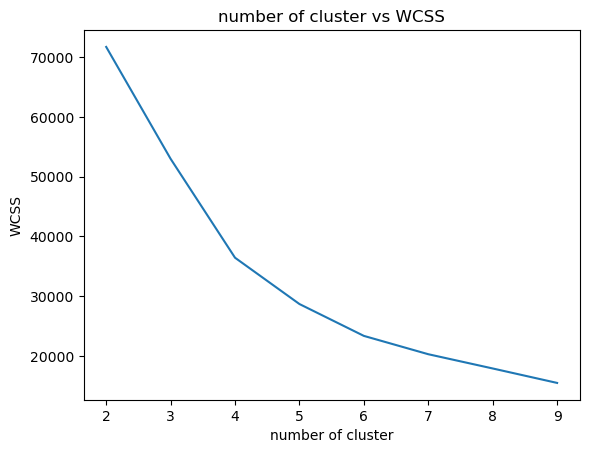

In [47]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
wcss = []
scores = []

for i in range(2,10):
    kmean = KMeans(n_clusters=i)
    y_pred_kmean = kmean.fit_predict(data_scaled)
    wcss.append(kmean.inertia_)
    scores.append(silhouette_score(data_scaled,y_pred_kmean))

plt.plot(range(2,10),wcss)
plt.title('number of cluster vs WCSS')
plt.xlabel('number of cluster')
plt.ylabel('WCSS')

In [48]:
kmean = KMeans(n_clusters=4)
y_pred_kmean = kmean.fit_predict(data_scaled)
y_pred_kmean

/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning:

The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning



array([0, 2, 0, ..., 0, 2, 1], dtype=int32)

In [49]:
final_data_kmean = pd.concat([data,pd.DataFrame(y_pred_kmean,columns=['Target'])],axis=1)
final_data_kmean

,User_Id,Recency,Frequency,Monetary,Target
0,0,401,1,4427,0
1,1,648,1,2490,2
2,2,446,1,3000,0
3,3,362,1,1620,0
4,4,275,1,700,0
...,...,...,...,...,...
33452,33514,581,3,5940,1
33453,33515,438,1,480,0
33454,33516,426,1,1320,0
33455,33517,669,1,2100,2


In [50]:
from sklearn.cluster import DBSCAN
db = DBSCAN(eps=0.5,min_samples=5)
y_pred_db = db.fit_predict(data_scaled)

In [51]:
np.unique(y_pred_db)



array([-1,  0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12])

In [52]:
final_data_db1 = pd.concat([data,pd.DataFrame(y_pred_db,columns=['Target'])],axis=1)
final_data_db1



,User_Id,Recency,Frequency,Monetary,Target
0,0,401,1,4427,0
1,1,648,1,2490,0
2,2,446,1,3000,0
3,3,362,1,1620,0
4,4,275,1,700,0
...,...,...,...,...,...
33452,33514,581,3,5940,4
33453,33515,438,1,480,0
33454,33516,426,1,1320,0
33455,33517,669,1,2100,0


In [53]:
final_data_db1.groupby('Target').describe().T



Target                    -1             0             1             2   \
User_Id   count  1.300000e+02  27035.000000   4383.000000    179.000000   
          mean   1.297035e+04  16298.723174  18497.055213  19520.240223   
          std    8.057524e+03   9651.942447   9611.324550   9348.347218   
          min    4.520000e+02      0.000000      8.000000     10.000000   
          25%    6.423750e+03   7994.500000  10189.000000  12208.500000   
          50%    1.238900e+04  15956.000000  19973.000000  21521.000000   
          75%    1.903925e+04  24524.500000  26676.500000  26647.000000   
          max    3.274700e+04  33517.000000  33513.000000  33278.000000   
Recency   count  1.300000e+02  27035.000000   4383.000000    179.000000   
          mean   5.810385e+02    506.503606    580.096509    600.743017   
          std    1.273958e+02    114.732164     97.699738     89.794215   
          min    0.000000e+00    113.000000    206.000000    313.000000   
          25%    5.590000e+02    419.000000    526.000000    567.500000   
          50%    6.410000e+02    491.000000    623.000000    641.000000   
          75%    6.557500e+02    623.000000    655.000000    655.000000   
          max    6.810000e+02    681.000000    681.000000    681.000000   
Frequency count  1.300000e+02  27035.000000   4383.000000    179.000000   
          mean   6.823077e+00      1.000000      2.000000      5.000000   
          std    4.907620e+00      0.000000      0.000000      0.000000   
          min    1.000000e+00      1.000000      2.000000      5.000000   
          25%    3.000000e+00      1.000000      2.000000      5.000000   
          50%    6.000000e+00      1.000000      2.000000      5.000000   
          75%    1.000000e+01      1.000000      2.000000      5.000000   
          max    2.900000e+01      1.000000      2.000000      5.000000   
Monetary  count  1.300000e+02  27035.000000   4383.000000    179.000000   
          mean   9.652401e+04   3123.432070   6031.177732  13737.005587   
          std    1.658698e+05   4297.682705   6883.745439  10219.151785   
          min    1.200000e+02     20.000000     40.000000    100.000000   
          25%    3.616225e+04   1400.000000   2239.000000   5191.000000   
          50%    6.146000e+04   1960.000000   3470.000000   9940.000000   
          75%    9.402525e+04   3000.000000   5944.000000  22114.000000   
          max    1.651838e+06  55850.000000  48401.000000  39010.000000   

Target                     3             4             5             6   \
User_Id   count    411.000000   1176.000000     72.000000     15.000000   
          mean   18943.233577  19493.099490  19316.819444  18793.066667   
          std     9290.369680   9426.587846   9981.331895  10004.451313   
          min       13.000000     35.000000    107.000000   2987.000000   
          25%    12002.500000  11784.250000  10126.000000   9160.500000   
          50%    20071.000000  21280.500000  21980.000000  18902.000000   
          75%    26554.000000  27123.250000  26749.500000  27439.000000   
          max    33508.000000  33518.000000  32479.000000  33052.000000   
Recency   count    411.000000   1176.000000     72.000000     15.000000   
          mean     597.819951    591.542517    634.277778    649.666667   
          std       88.230666     93.894200     35.050154     18.325106   
          min      304.000000    254.000000    508.000000    615.000000   
          25%      576.000000    562.000000    622.750000    644.500000   
          50%      636.000000    635.000000    648.000000    648.000000   
          75%      655.000000    655.000000    655.000000    664.000000   
          max      681.000000    681.000000    674.000000    671.000000   
Frequency count    411.000000   1176.000000     72.000000     15.000000   
          mean       4.000000      3.000000      6.000000      7.000000   
          std        0.000000      0.000000      0.000000      0.000000   
          min        4.0

In [54]:
db = DBSCAN(eps=0.4,min_samples=5)
y_pred_db_2 = db.fit_predict(data_scaled)


In [55]:

np.unique(y_pred_db_2)



array([-1,  0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14])

In [56]:
final_data_db2 = pd.concat([data,pd.DataFrame(y_pred_db_2,columns=['Target'])],axis=1)


final_data_db2.groupby('Target').describe().T

Target                    -1             0             1             2   \
User_Id   count  1.830000e+02  27026.000000   4366.000000    148.000000   
          mean   1.445426e+04  16298.511729  18500.628264  19083.270270   
          std    8.858028e+03   9652.200087   9608.162105   9882.560095   
          min    2.700000e+02      0.000000      8.000000     10.000000   
          25%    6.581500e+03   7994.250000  10188.500000  10008.750000   
          50%    1.304200e+04  15956.500000  19987.500000  21536.500000   
          75%    2.129500e+04  24523.750000  26677.750000  26720.250000   
          max    3.274700e+04  33517.000000  33513.000000  33278.000000   
Recency   count  1.830000e+02  27026.000000   4366.000000    148.000000   
          mean   5.600656e+02    506.505957    580.790655    635.864865   
          std    1.274481e+02    114.743911     97.108917     39.412117   
          min    0.000000e+00    113.000000    206.000000    500.000000   
          25%    5.025000e+02    418.250000    528.000000    629.500000   
          50%    6.100000e+02    491.000000    624.000000    648.000000   
          75%    6.550000e+02    623.000000    655.000000    662.000000   
          max    6.810000e+02    681.000000    681.000000    681.000000   
Frequency count  1.830000e+02  27026.000000   4366.000000    148.000000   
          mean   6.032787e+00      1.000000      2.000000      5.000000   
          std    4.496521e+00      0.000000      0.000000      0.000000   
          min    1.000000e+00      1.000000      2.000000      5.000000   
          25%    3.000000e+00      1.000000      2.000000      5.000000   
          50%    5.000000e+00      1.000000      2.000000      5.000000   
          75%    8.000000e+00      1.000000      2.000000      5.000000   
          max    2.900000e+01      1.000000      2.000000      5.000000   
Monetary  count  1.830000e+02  27026.000000   4366.000000    148.000000   
          mean   7.751822e+04   3108.763006   5913.377920  11823.344595   
          std    1.430715e+05   4221.508391   6583.999505   9903.035067   
          min    1.200000e+02     20.000000     40.000000    100.000000   
          25%    2.604000e+04   1400.000000   2234.000000   4472.500000   
          50%    4.800000e+04   1960.000000   3460.000000   7682.000000   
          75%    7.729050e+04   2999.750000   5865.500000  18525.750000   
          max    1.651838e+06  55850.000000  46760.000000  39010.000000   

Target                     3             4             5             6   \
User_Id   count    411.000000   1169.000000     37.000000     10.000000   
          mean   18943.233577  19553.733961  17859.621622  19084.900000   
          std     9290.369680   9408.679395  10691.691115  10129.816708   
          min       13.000000     35.000000    107.000000   1549.000000   
          25%    12002.500000  11997.000000   8117.000000  13695.500000   
          50%    20071.000000  21343.000000  18485.000000  20683.000000   
          75%    26554.000000  27143.000000  27935.000000  25421.250000   
          max    33508.000000  33518.000000  32264.000000  30890.000000   
Recency   count    411.000000   1169.000000     37.000000     10.000000   
          mean     597.819951    591.709153    636.162162    399.400000   
          std       88.230666     93.575564     27.743381     30.000741   
          min      304.000000    295.000000    565.000000    350.000000   
          25%      576.000000    562.000000    622.000000    378.250000   
          50%      636.000000    635.000000    644.000000    406.000000   
          75%      655.000000    655.000000    655.000000    424.250000   
          max      681.000000    681.000000    674.000000    432.000000   
Frequency count    411.000000   1169.000000     37.000000     10.000000   
          mean       4.000000      3.000000      6.000000      2.000000   
          std        0.000000      0.000000      0.000000      0.000000   
          min        4.0